# 01 — Dataset exploration

**Objective:** inspect the tracked TinyDevAssist seed dataset and reproduce the fixed-seed splits.
This is a real, small, project-authored 36-row sample, not a production benchmark.
The notebook calls the same `prepare_dataset` function as the CLI; no independent data-cleaning logic.

**Requirements:** Python 3.11+, `pandas`, `matplotlib`, and the editable project package (or run from the repository root). No model download needed.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from tinydevassist.data import prepare_dataset

root = Path.cwd()
if not (root / "pyproject.toml").exists():
    root = root.parent

source = root / "data/samples/developer_support_v1.jsonl"
output_dir = root / "data/processed"
manifest = prepare_dataset(source, output_dir, seed=42)
print("Source SHA-256:", manifest["source_sha256"])
print("Retained:", manifest["retained_count"])
print("Split sizes:", {name: info["count"] for name, info in manifest["splits"].items()})

Source SHA-256: 92ffc379ffe09d71052d9a7cfc9c9b4fe740c540cb7955e4347e2f646bef151f
Retained: 36
Split sizes: {'train': 24, 'validation': 6, 'test': 6}


In [2]:
rows = []
for split in ("train", "validation", "test"):
    for line in (output_dir / f"{split}.jsonl").read_text(encoding="utf-8").splitlines():
        record = json.loads(line)
        rows.append(
            {
                "split": split,
                "id": record["id"],
                "category": record["category"],
                "prompt_words": len(record["instruction"].split()),
                "answer_words": len(record["response"].split()),
            }
        )
df = pd.DataFrame(rows)
display(df.groupby(["category", "split"]).size().unstack(fill_value=0))
display(df[["prompt_words", "answer_words"]].describe())

split,test,train,validation
category,,,
api,1,4,1
debugging,1,4,1
git,1,4,1
http,1,4,1
ops,1,4,1
python,1,4,1


,prompt_words,answer_words
count,36.000000,36.000000
mean,9.250000,28.777778
std,1.380993,3.727206
min,7.000000,17.000000
25%,8.000000,26.750000
50%,9.000000,28.500000
75%,10.000000,31.000000
max,12.000000,35.000000


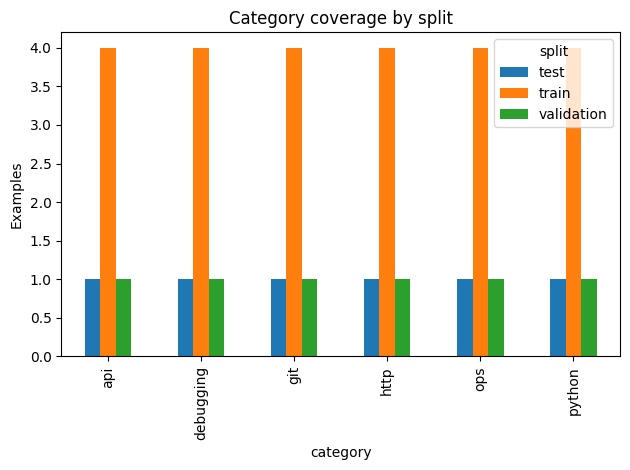

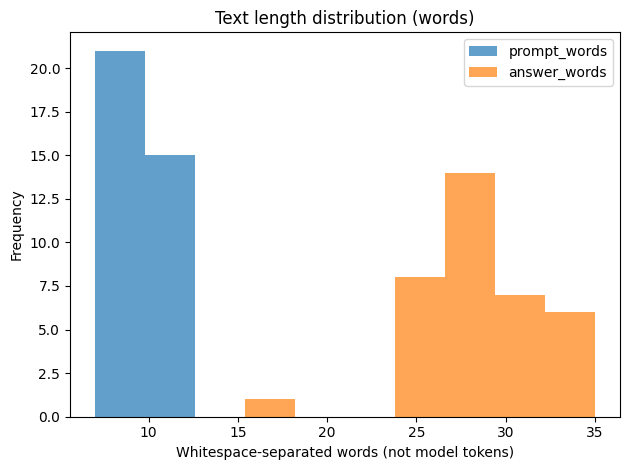

In [3]:
counts = df.groupby(["category", "split"]).size().unstack(fill_value=0)
ax = counts.plot(kind="bar", title="Category coverage by split")
ax.set_ylabel("Examples")
plt.tight_layout()
plt.show()

ax = df[["prompt_words", "answer_words"]].plot(
    kind="hist", bins=10, alpha=0.7, title="Text length distribution (words)"
)
ax.set_xlabel("Whitespace-separated words (not model tokens)")
plt.tight_layout()
plt.show()

## Interpretation and limitations

- The tracked source contains **36 illustrative questions**, with 6 categories; seed 42 produces **24/6/6** train/validation/test examples. Verify the computed tables above before using these numbers in a report.
- Word counts are *not* tokenizer token counts. Token counts require downloading the chosen model tokenizer.
- The held-out rows originate from the same authored seed set; they are not an independent generalization test.
- Generated splits and manifests are ignored by Git. Never train on validation or test examples.